**MDS clássico: reconstruindo o mapa a partir das distâncias**
**Referência:** Murphy, *Probabilistic Machine Learning: An Introduction* (2022), Seção 20.4.4 (*Multidimensional scaling*).

**A pergunta deste notebook:** se eu te der **só** a tabela de distâncias entre 14 cidades, sem nenhuma coordenada, dá para redesenhar o mapa?

**Roteiro**
- Etapa 0: Dados (coordenadas reais, que vamos "esconder")
- Etapa 1: Matriz de distâncias $D$ (haversine)
- Etapa 2: MDS clássico: $B = -\tfrac12 H D^{(2)} H$, $\;Y = V_d\Lambda_d^{1/2}$
- Etapa 3: Comparar com o mapa real
- Etapa 4: Por que o mapa sai girado/espelhado (Procrustes)
- Etapa 5: O que os autovalores contam (curvatura da Terra!)
- Etapa 6: arco × corda, tirando a prova da curvatura
- Conclusões

**Etapa 0: Dados**

Usamos `float64` porque, mais à frente, vamos olhar autovalores **muito pequenos** e precisamos distinguir "zero de verdade" de "erro de arredondamento". Em `float32` (7 dígitos) isso fica impossível quando os autovalores grandes são da ordem de $10^6$.

As coordenadas servem **só** para (1) calcular as distâncias e (2) conferir o resultado no final. O MDS em si **nunca** as vê.

In [1]:
import torch
import matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)
plt.rcParams["figure.dpi"] = 110

cidades = {
    "Pres. Prudente": (-22.12, -51.39), "São Paulo": (-23.55, -46.63),
    "Campinas": (-22.91, -47.06),       "Bauru": (-22.31, -49.06),
    "Ribeirão Preto": (-21.18, -47.81), "S.J. Rio Preto": (-20.81, -49.38),
    "Londrina": (-23.31, -51.16),       "Maringá": (-23.42, -51.94),
    "Curitiba": (-25.43, -49.27),       "Florianópolis": (-27.59, -48.55),
    "Rio de Janeiro": (-22.91, -43.17), "Belo Horizonte": (-19.92, -43.94),
    "Campo Grande": (-20.44, -54.65),   "Brasília": (-15.79, -47.88),
}
nomes = list(cidades.keys())
coords = torch.tensor(list(cidades.values()))
N = len(nomes)
print(N, "cidades; coords.shape =", tuple(coords.shape))

14 cidades; coords.shape = (14, 2)


**Etapa 1: Matriz de distâncias pela fórmula de haversine**

**O que a fórmula mede**
A distância **sobre a superfície** da esfera (o caminho que um avião faria), não a reta que atravessa a Terra. Com latitudes $\varphi$, longitudes $\lambda$ em **radianos** e $R = 6371$ km:

$$
a_{ij} = \sin^2\!\left(\frac{\varphi_j - \varphi_i}{2}\right) + \cos\varphi_i\cos\varphi_j\,\sin^2\!\left(\frac{\lambda_j - \lambda_i}{2}\right),
\qquad
d_{ij} = 2R\,\arcsin\!\big(\sqrt{a_{ij}}\big).
$$

Intuição: $a_{ij} \in [0,1]$ mede "quanto da meia-volta da Terra" separa os dois pontos; $2\arcsin\sqrt{a}$ converte isso no **ângulo central** $\theta$ entre eles, e $R\theta$ é o comprimento do arco.

**O truque de programação: *broadcasting***
Queremos $d_{ij}$ para **todos** os $N^2$ pares sem laço `for`. Se `phi` tem shape `(N,)`:
- `phi[:, None]` tem shape `(N, 1)` → uma **coluna**, o valor de $\varphi_i$ repetido ao longo da linha $i$
- `phi[None, :]` tem shape `(1, N)` → uma **linha**, o valor de $\varphi_j$ repetido ao longo da coluna $j$

Ao subtrair, o PyTorch "estica" ambos para `(N, N)` e a entrada $(i,j)$ vira $\varphi_j - \varphi_i$. É a mesma ideia da fórmula $\|\mathbf a\|^2 + \|\mathbf b\|^2 - 2\mathbf a^\top\mathbf b$ que usamos no kernel RBF.

In [2]:
def haversine_matriz(coords, R=6371.0):
    rad = torch.deg2rad(coords)
    phi, lam = rad[:, 0], rad[:, 1]

    dphi = phi[None, :] - phi[:, None]
    dlam = lam[None, :] - lam[:, None]
    cos_i = torch.cos(phi)[:, None]
    cos_j = torch.cos(phi)[None, :]

    a = torch.sin(dphi / 2)**2 + cos_i * cos_j * torch.sin(dlam / 2)**2
    return 2 * R * torch.arcsin(torch.sqrt(a.clamp(0, 1)))

D = haversine_matriz(coords)

**Conferências (sempre faça!)**
Uma matriz de distâncias **tem** que ser simétrica ($d_{ij} = d_{ji}$) e ter diagonal zero ($d_{ii}=0$). E um valor conhecido serve de teste de sanidade.

In [3]:
print("simétrica?        ", torch.allclose(D, D.T))
print("diagonal zero?    ", torch.allclose(D.diag(), torch.zeros(N)))
print(f"P. Prudente -> SP: {D[0, 1]:.0f} km")
print(f"Florianópolis -> Brasília (o par mais distante?): {D[9, 13]:.0f} km;  máximo da matriz: {D.max():.0f} km")

simétrica?         True
diagonal zero?     True
P. Prudente -> SP: 513 km
Florianópolis -> Brasília (o par mais distante?): 1314 km;  máximo da matriz: 1314 km


**Etapa 2: MDS clássico**

A derivação em três passos:

1. Se os pontos existissem em $\mathbb{R}^p$ e estivessem centrados, a matriz de produtos internos $B = YY^\top$ se relaciona com as distâncias por
$$ d_{ij}^2 = b_{ii} + b_{jj} - 2b_{ij}. $$
2. Isolando $b_{ij}$ com a **dupla centralização**:
$$ B = -\tfrac12\,H\,D^{(2)}\,H,\qquad H = I_N - \tfrac1N\mathbf 1\mathbf 1^\top. $$
3. Fatorando $B = V\Lambda V^\top$ e ficando com os $d$ maiores autovalores:
$$ Y = V_d\,\Lambda_d^{1/2}. $$

**Três detalhes que costumam dar erro**

**(a) `D**2` e não `D @ D`.** $D^{(2)}$ é o quadrado **elemento a elemento** ($[D^{(2)}]_{ij} = d_{ij}^2$). `D @ D` é produto de matrizes, $\sum_k d_{ik}d_{kj}$, que não tem nada a ver.

**(b) O que $H$ faz.** Para qualquer matriz $M$:
- $HM$ subtrai de cada coluna a sua média (centraliza as colunas);
- $MH$ subtrai de cada linha a sua média (centraliza as linhas).

Então $HD^{(2)}H$ executa exatamente $d_{ij}^2 - \bar d^{\,2}_{i\cdot} - \bar d^{\,2}_{\cdot j} + \bar d^{\,2}_{\cdot\cdot}$, a fórmula entrada a entrada da derivação. Vamos **verificar isso numericamente** abaixo em vez de só acreditar.

**(c) `eigh` devolve autovalores em ordem CRESCENTE.** Os que queremos (os maiores) ficam no **fim**. Sem reordenar, você pegaria as 2 piores direções.

**Por que $V_d\Lambda_d^{1/2}$?**
Queremos $Y$ com $YY^\top \approx B$. Como $B = V\Lambda V^\top = (V\Lambda^{1/2})(V\Lambda^{1/2})^\top$, a escolha natural é $Y = V\Lambda^{1/2}$. Ficar só com as $d$ primeiras colunas dá a **melhor aproximação de posto $d$** de $B$ (teorema de Eckart–Young, o mesmo que justifica truncar o PCA).

Repare: $\sqrt{\lambda_k}$ multiplica a **coluna** $k$ de $V$. Em código, `V[:, :d] * torch.sqrt(lam[:d])` faz isso por *broadcasting*: um vetor `(d,)` multiplica cada linha de uma matriz `(N, d)`, coluna a coluna.

In [4]:
def mds_classico(D, d=2):
    N = D.shape[0]
    D2 = D**2
    H = torch.eye(N) - torch.ones(N, N) / N
    B = -0.5 * H @ D2 @ H

    lam, V = torch.linalg.eigh(B)
    ordem = torch.argsort(lam, descending=True)
    lam, V = lam[ordem], V[:, ordem]

    Y = V[:, :d] * torch.sqrt(lam[:d])
    return Y, lam, B

Y, autovalores, B = mds_classico(D, d=2)
print("Y.shape =", tuple(Y.shape))

Y.shape = (14, 2)


**Verificando a dupla centralização entrada a entrada**
Se o raciocínio do item (b) está certo, a fórmula matricial e a fórmula com médias têm que dar **a mesma** $B$.

In [5]:
D2 = D**2
media_linhas  = D2.mean(dim=1, keepdim=True)
media_colunas = D2.mean(dim=0, keepdim=True)
media_geral   = D2.mean()
B_entradas = -0.5 * (D2 - media_linhas - media_colunas + media_geral)

print("H D² H  ==  fórmula com médias? ", torch.allclose(B, B_entradas))
print("linhas de B somam zero?         ", torch.allclose(B.sum(1), torch.zeros(N)))

H D² H  ==  fórmula com médias?  True
linhas de B somam zero?          True


A segunda checagem é a **consequência do Passo 2** da derivação: como fixamos a origem no centroide ($\sum_i \mathbf y_i = \mathbf 0$), as linhas e colunas de $B$ somam zero. Logo o vetor $\mathbf 1$ é autovetor de $B$ com autovalor $0$, e todos os outros autovetores são ortogonais a ele, ou seja, as coordenadas do MDS **sempre saem centradas**.

In [6]:
print("média das coordenadas do MDS:", Y.mean(0))

média das coordenadas do MDS: tensor([-4.0602e-15, -6.0904e-15])


**Etapa 3: Comparando com o mapa real**

À esquerda, longitude × latitude (o "mapa" de verdade). À direita, o que o MDS reconstruiu **só a partir de $D$**.

Os eixos do MDS estão em **km** (porque $D$ está em km): a distância entre dois pontos no gráfico da direita aproxima a distância real entre as cidades. Os eixos da esquerda estão em **graus**, e 1° de longitude $\neq$ 1° de latitude em km (a $22^\circ$S, 1° de longitude $\approx 111\cos 22^\circ \approx 103$ km). Por isso as formas são parecidas mas não idênticas.

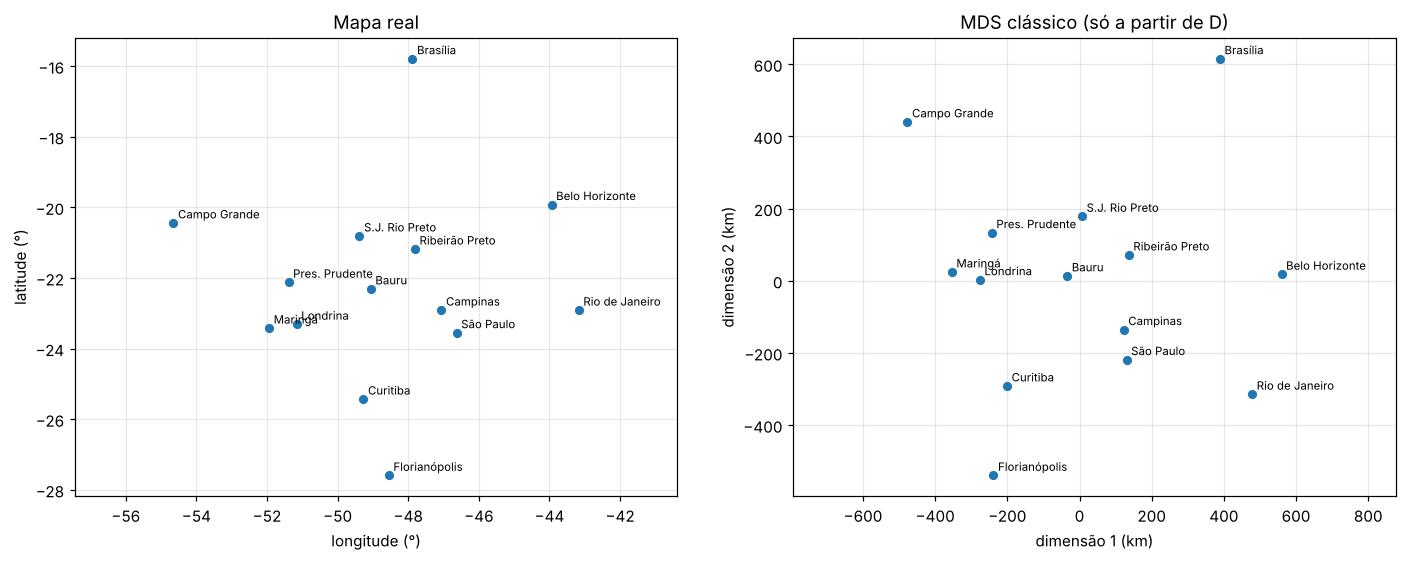

In [7]:
def plot_mapa(ax, P, titulo, xlabel, ylabel):
    ax.scatter(P[:, 0], P[:, 1], s=25, color="tab:blue", zorder=3)
    for k, nome in enumerate(nomes):
        ax.annotate(nome, (P[k, 0], P[k, 1]), fontsize=7.5,
                    xytext=(3, 3), textcoords="offset points")
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_aspect("equal", adjustable="datalim"); ax.grid(alpha=0.3)

mapa_real = coords[:, [1, 0]]

fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
plot_mapa(ax[0], mapa_real, "Mapa real", "longitude (°)", "latitude (°)")
plot_mapa(ax[1], Y, "MDS clássico (só a partir de D)", "dimensão 1 (km)", "dimensão 2 (km)")
plt.tight_layout(); plt.show()

**Medida objetiva: as distâncias foram preservadas?**
Calculamos as distâncias **no mapa do MDS**, $\|\mathbf y_i - \mathbf y_j\|$, e comparamos com as distâncias originais $d_{ij}$. `torch.cdist` calcula todas as distâncias euclidianas par a par.

In [8]:
D_mds = torch.cdist(Y, Y)
erro = (D_mds - D).abs()
print(f"erro médio:  {erro.mean():.2f} km")
print(f"erro máximo: {erro.max():.2f} km   (entre distâncias de até {D.max():.0f} km)")

erro médio:  0.11 km
erro máximo: 0.83 km   (entre distâncias de até 1314 km)


**Etapa 4: Por que o mapa sai girado ou espelhado?**

Se $Y$ é solução, então $YQ$ também é, para **qualquer** matriz ortogonal $Q$ ($Q^\top Q = I$, ou seja, rotação ou reflexão):

$$
\|\mathbf y_i Q - \mathbf y_j Q\|^2 = (\mathbf y_i - \mathbf y_j)\,QQ^\top(\mathbf y_i - \mathbf y_j)^\top = \|\mathbf y_i - \mathbf y_j\|^2 .
$$

As distâncias não mudam, então **nenhuma** informação em $D$ distingue $Y$ de $YQ$. Do lado da álgebra: autovetores são definidos a menos de sinal ($\mathbf v$ e $-\mathbf v$ são ambos autovetores), e trocar o sinal de uma coluna de $Y$ é exatamente uma reflexão. Junto com a translação perdida no Passo 2, o MDS determina a configuração **a menos de um movimento rígido**.

**Provando: alinhar o MDS ao mapa real (Procrustes ortogonal)**
Para comparar de forma justa, convertemos o mapa real para km com uma projeção plana simples
$$ x = R\,\lambda\cos\varphi_0,\qquad y = R\,\varphi \quad(\varphi_0 = \text{latitude média}) $$
e procuramos a rotação/reflexão $Q$ que melhor encaixa $Y$ nele:
$$ \min_{Q^\top Q = I}\ \|YQ - X\|_F^2 \quad\Longrightarrow\quad Q = UW^\top,\ \text{ onde } Y^\top X = U\Sigma W^\top \text{ (SVD).} $$
Se depois do alinhamento os pontos caírem em cima uns dos outros, fica provado que a diferença era **só** rotação/reflexão.

Q =
 tensor([[ 0.9030,  0.4290],
        [-0.4290,  0.9030]])
det(Q) = 1.0  (+1 = rotação pura, -1 = envolve reflexão)


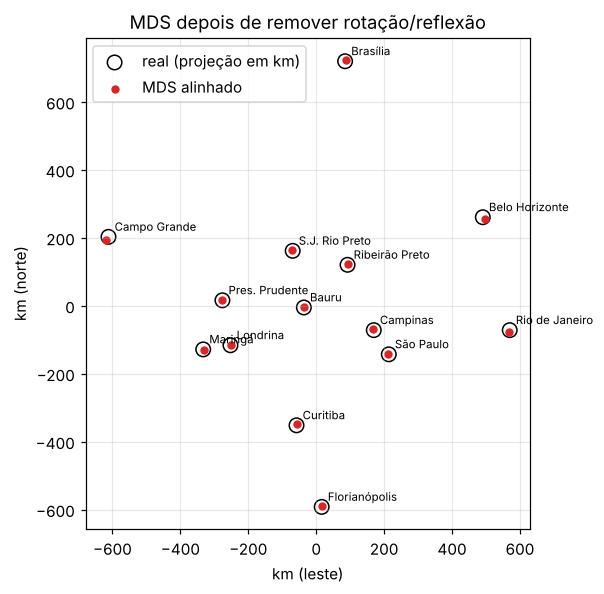

distância média entre real e MDS alinhado: 4.1 km


In [9]:
R = 6371.0
rad = torch.deg2rad(coords)
phi0 = rad[:, 0].mean()
X_km = torch.stack([R * rad[:, 1] * torch.cos(phi0), R * rad[:, 0]], dim=1)
X_km = X_km - X_km.mean(0)

U, S, Wt = torch.linalg.svd(Y.T @ X_km)
Q = U @ Wt
Y_alinhado = Y @ Q
print("Q =\n", Q.round(decimals=3))
print("det(Q) =", round(torch.det(Q).item(), 3), " (+1 = rotação pura, -1 = envolve reflexão)")

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(X_km[:, 0], X_km[:, 1], s=90, facecolors="none", edgecolors="k", label="real (projeção em km)")
ax.scatter(Y_alinhado[:, 0], Y_alinhado[:, 1], s=20, color="tab:red", label="MDS alinhado")
for k, nome in enumerate(nomes):
    ax.annotate(nome, (X_km[k, 0], X_km[k, 1]), fontsize=7.5, xytext=(4, 4), textcoords="offset points")
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_xlabel("km (leste)"); ax.set_ylabel("km (norte)")
ax.set_title("MDS depois de remover rotação/reflexão")
plt.tight_layout(); plt.show()
print(f"distância média entre real e MDS alinhado: {(Y_alinhado - X_km).norm(dim=1).mean():.1f} km")

A pequena diferença restante vem da **projeção plana** que usamos para o mapa "real" (ela também distorce um pouco), não do MDS. Repare que o erro nas **distâncias** (Etapa 3) era bem menor.

**Etapa 5: O que os autovalores contam**

Se as distâncias viessem de pontos **num plano**, $B$ teria posto 2: exatamente 2 autovalores positivos e o resto **zero**. Vamos ver.

In [10]:
print(" k   autovalor λ_k")
for k, l in enumerate(autovalores, start=1):
    print(f"{k:2d}   {l: .4e}")

positivos = autovalores.clamp_min(0)
print(f"\nfração 'explicada' pelas 2 primeiras dimensões: {positivos[:2].sum() / positivos.sum():.5f}")

 k   autovalor λ_k
 1    1.3302e+06
 2    1.1687e+06
 3    6.7396e+02
 4    7.8049e-01
 5    2.3509e-02
 6    1.4692e-06
 7    4.3506e-07
 8   -1.2120e-11
 9   -1.1016e-06
10   -2.4501e-05
11   -1.5443e-02
12   -7.6125e-02
13   -2.1551e+02
14   -1.3996e+03

fração 'explicada' pelas 2 primeiras dimensões: 0.99973


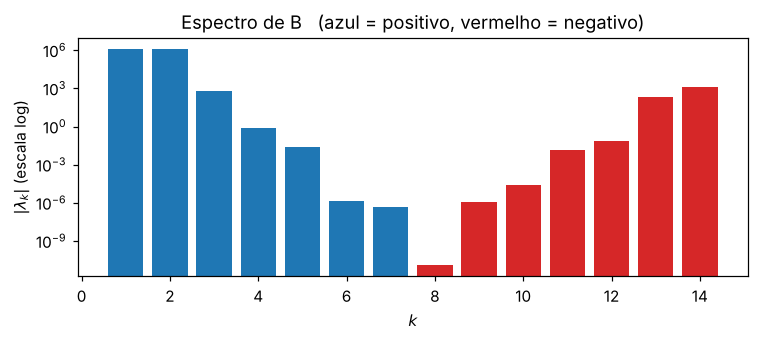

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.2))
cores = ["tab:blue" if l > 0 else "tab:red" for l in autovalores]
ax.bar(range(1, N + 1), autovalores.abs(), color=cores)
ax.set_yscale("log")
ax.set_xlabel("$k$"); ax.set_ylabel(r"$|\lambda_k|$ (escala log)")
ax.set_title("Espectro de B   (azul = positivo, vermelho = negativo)")
plt.tight_layout(); plt.show()

**Como ler este espectro**

- **$\lambda_1, \lambda_2 \sim 10^6$**: as duas direções do "mapa". Juntas carregam praticamente toda a estrutura, por isso o 2D funciona tão bem.
- **$\lambda_3$ positivo, mas ~1000 vezes menor**: uma **terceira dimensão** pequena. É a **curvatura da Terra**: numa região de ~1500 km, a superfície "abaula" para fora do plano tangente, e o MDS detecta esse pouquinho de profundidade.
- **Autovalores negativos** (vermelho): impossíveis se $D$ fosse euclidiana, porque $B = YY^\top$ seria semidefinida positiva ($\mathbf a^\top B\mathbf a = \|Y^\top\mathbf a\|^2 \ge 0$). Eles aparecem porque a haversine mede o **arco** sobre a esfera, que é **mais longo** que a reta (corda) entre os pontos. Não existe nenhuma configuração de pontos em $\mathbb{R}^p$, para nenhum $p$, com essas distâncias exatas. O MDS "acusa" isso com $\lambda < 0$, e simplesmente os descartamos.
- **E os autovalores bem pequenos ($\lambda_4,\lambda_5,\dots$)?** Cuidado para não chamá-los de "zero" cedo demais. O nível de ruído de arredondamento em `float64` é da ordem de $N\,\varepsilon\,|\lambda_1| \approx 14 \times 2{,}2\times10^{-16}\times 1{,}3\times10^{6} \approx 4\times10^{-9}$. Só $\lambda_8 \approx 10^{-11}$ está abaixo disso, e ele **tem** que ser zero, porque é o autovalor do vetor $\mathbf 1$ (as linhas de $B$ somam zero). Valores como $0{,}78$ ou $-0{,}076$ são pequenos, mas **não** são arredondamento: também são resíduo do arco não ser euclidiano. A Etapa 6 confirma isso.

Isso é um diagnóstico útil na prática: **autovalores negativos grandes indicam que a sua medida de dissimilaridade não é euclidiana**, e o MDS clássico vai distorcer.

**Etapa 6: arco × corda, tirando a prova da curvatura**

Se a explicação da Etapa 5 está certa, dá para fazer uma previsão **antes** de rodar: trocando o arco pela **corda** (a reta que atravessa a Terra), as distâncias passam a ser euclidianas de verdade, porque são distâncias entre pontos de $\mathbb{R}^3$. Então esperamos:

1. **nenhum autovalor negativo** (fora o ruído numérico);
2. **exatamente 3 autovalores positivos** ($B$ com posto 3);
3. **$\lambda_3$ continua lá**, porque a profundidade da calota esférica é real, não é artefato da haversine.

**A corda sai de graça da haversine**
Se $\theta$ é o ângulo central entre os pontos, o arco é $R\theta$ e a corda é $2R\sin(\theta/2)$. Como $\theta = 2\arcsin\sqrt{a}$, temos $\sin(\theta/2) = \sqrt a$:

$$
c_{ij} = 2R\sqrt{a_{ij}} \qquad\text{e}\qquad d_{ij} = 2R\arcsin\!\big(\sqrt{a_{ij}}\big) \ \ge\ c_{ij},
$$

porque $\arcsin x \ge x$ para $x\in[0,1]$. Ou seja: é a mesma fórmula, só sem o `arcsin`.

Para decidir o que é "zero", usamos o critério padrão de posto numérico (o mesmo do `numpy.linalg.matrix_rank`): $|\lambda| < N\,\varepsilon\,|\lambda_1|$.

In [12]:
def corda_matriz(coords, R=6371.0):
    rad = torch.deg2rad(coords)
    phi, lam = rad[:, 0], rad[:, 1]
    dphi = phi[None, :] - phi[:, None]
    dlam = lam[None, :] - lam[:, None]
    a = torch.sin(dphi / 2)**2 + torch.cos(phi)[:, None] * torch.cos(phi)[None, :] * torch.sin(dlam / 2)**2
    return 2 * R * torch.sqrt(a.clamp(0, 1))

D_corda = corda_matriz(coords)
print(f"arco - corda: no máximo {(D - D_corda).max():.2f} km  (entre distâncias de até {D.max():.0f} km)")

_, autoval_corda, _ = mds_classico(D_corda, d=3)

def tolerancia(lam):
    return len(lam) * torch.finfo(lam.dtype).eps * lam.abs().max()

tol_arco, tol_corda = tolerancia(autovalores), tolerancia(autoval_corda)
print(f"tolerância numérica: {tol_arco:.1e} (arco), {tol_corda:.1e} (corda)\n")

print(" k      arco (haversine)      corda")
for k in range(N):
    print(f"{k+1:2d}   {autovalores[k]: .4e}      {autoval_corda[k]: .4e}")

for nome, lam, tol in [("arco ", autovalores, tol_arco), ("corda", autoval_corda, tol_corda)]:
    pos = (lam > tol).sum().item(); neg = (lam < -tol).sum().item(); zer = N - pos - neg
    print(f"\n{nome}: {pos} positivos, {neg} negativos, {zer} zero(s) numérico(s)", end="")

arco - corda: no máximo 2.33 km  (entre distâncias de até 1314 km)
tolerância numérica: 4.1e-09 (arco), 4.1e-09 (corda)

 k      arco (haversine)      corda
 1    1.3302e+06       1.3271e+06
 2    1.1687e+06       1.1653e+06
 3    6.7396e+02       2.0743e+03
 4    7.8049e-01       2.6119e-10
 5    2.3509e-02       1.4139e-10
 6    1.4692e-06       8.8726e-11
 7    4.3506e-07       4.4157e-11
 8   -1.2120e-11       1.3596e-11
 9   -1.1016e-06       1.7335e-12
10   -2.4501e-05      -1.9897e-11
11   -1.5443e-02      -6.0691e-11
12   -7.6125e-02      -8.1667e-11
13   -2.1551e+02      -2.0227e-10
14   -1.3996e+03      -4.5294e-10

arco : 7 positivos, 6 negativos, 1 zero(s) numérico(s)
corda: 3 positivos, 0 negativos, 11 zero(s) numérico(s)

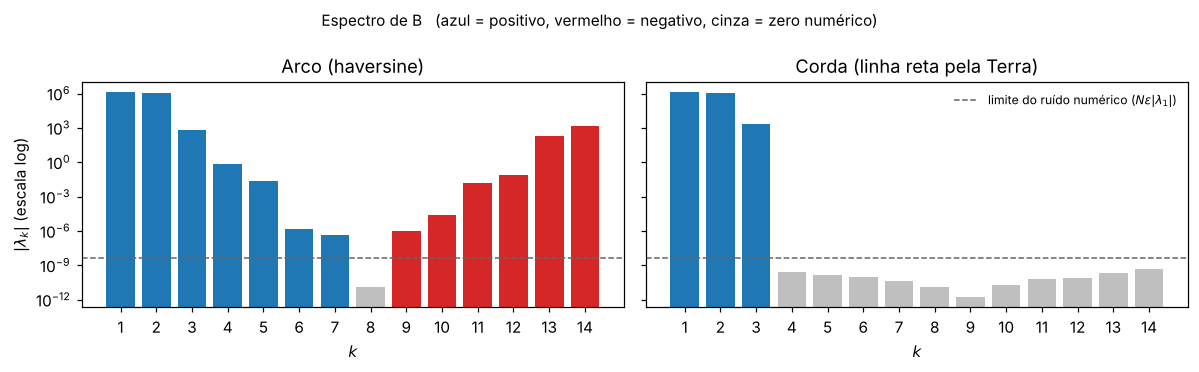

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, lam, tol, titulo in [(axes[0], autovalores, tol_arco, "Arco (haversine)"),
                             (axes[1], autoval_corda, tol_corda, "Corda (linha reta pela Terra)")]:
    cores = ["0.75" if l.abs() < tol else ("tab:blue" if l > 0 else "tab:red") for l in lam]
    ax.bar(range(1, N + 1), lam.abs(), color=cores)
    ax.axhline(tol, color="0.4", ls="--", lw=1, label=r"limite do ruído numérico ($N\varepsilon|\lambda_1|$)")
    ax.set_yscale("log"); ax.set_title(titulo); ax.set_xlabel("$k$")
    ax.set_xticks(range(1, N + 1))
axes[1].legend(loc="upper right", fontsize=8, frameon=False)
axes[0].set_ylabel(r"$|\lambda_k|$ (escala log)")
fig.suptitle("Espectro de B   (azul = positivo, vermelho = negativo, cinza = zero numérico)", fontsize=10)
plt.tight_layout(); plt.show()

**As três previsões se confirmaram**
- **Com a corda, os negativos somem**: todos ficam abaixo da linha de ruído. A corda é uma distância euclidiana legítima, e $B$ volta a ser semidefinida positiva.
- **Posto exatamente 3**: 3 autovalores positivos e 11 zeros numéricos. O MDS descobriu, só pela tabela, que os pontos vivem em $\mathbb{R}^3$.
- **$\lambda_3$ não só continua como fica maior** (≈ 2 070 contra ≈ 670 com o arco). Com a haversine, parte dessa profundidade "vaza" para as direções negativas: o excesso do arco sobre a corda não cabe em nenhuma configuração euclidiana, e a decomposição divide esse excesso entre direções positivas e negativas. Com a corda, não há o que vazar.

E repare na escala: arco e corda diferem em **no máximo ~2 km**, numa tabela com distâncias de até 1 300 km. Uma diferença de 0,2% basta para tirar a matriz do mundo euclidiano, e o espectro denuncia isso na hora.

**Prova final: a corda reconstrói a Terra exatamente**
Se as cordas vêm de pontos reais na esfera, o MDS em 3D deve reproduzir essas distâncias **sem erro** (só arredondamento). E os 3 autovalores devem ser exatamente os autovalores de $X^\top X$, onde $X$ são as posições 3D reais (centradas), porque $B = XX^\top$ e $XX^\top$ e $X^\top X$ têm os mesmos autovalores não nulos.

In [14]:
Y3, _, _ = mds_classico(D_corda, d=3)
print(f"erro máximo nas distâncias (MDS 3D vs. corda): {(torch.cdist(Y3, Y3) - D_corda).abs().max():.1e} km")

rad = torch.deg2rad(coords)
phi, lam = rad[:, 0], rad[:, 1]
X3 = R * torch.stack([torch.cos(phi) * torch.cos(lam),
                      torch.cos(phi) * torch.sin(lam),
                      torch.sin(phi)], dim=1)
X3 = X3 - X3.mean(0)

print("autovalores de X^T X  :", torch.linalg.eigvalsh(X3.T @ X3).flip(0))
print("3 maiores do MDS-corda:", autoval_corda[:3])

erro máximo nas distâncias (MDS 3D vs. corda): 2.3e-13 km
autovalores de X^T X  : tensor([1327078.5311, 1165290.2491,    2074.2715])
3 maiores do MDS-corda: tensor([1327078.5311, 1165290.2491,    2074.2715])


Bate até a última casa: o $\lambda_3$ do MDS **é** a variância (vezes $N$) dos pontos na direção perpendicular ao "plano do mapa", ou seja, o quanto a calota esférica que contém as 14 cidades é abaulada.

**A ponte para o Isomap**
Aqui as distâncias **sobre a superfície** (arcos) quase não diferem das retas, porque a região é pequena comparada ao raio da Terra. No *Swiss roll* é o contrário: dois pontos podem estar perto em linha reta (atravessando o "rocambole") e longe **andando sobre ele**. O Isomap é exatamente este notebook, trocando a haversine por uma distância geodésica estimada num grafo de vizinhos.

**Conclusões**

- **Só a tabela de distâncias basta para redesenhar o mapa.** O MDS clássico reconstruiu as 14 cidades com erro médio de ~0,1 km nas distâncias, sem nunca ver uma coordenada.
- **O mapa sai certo a menos de translação, rotação e reflexão**, porque nada disso altera distâncias. A Procrustes mostrou que a diferença para o mapa real era só isso.
- **O espectro de $B$ é um diagnóstico.** O número de autovalores positivos relevantes diz quantas dimensões os dados realmente têm; autovalores negativos dizem que a dissimilaridade usada não é euclidiana.
- **O MDS enxergou a curvatura da Terra.** Com a corda, $B$ tem posto exatamente 3 e $\lambda_3$ coincide com a profundidade real da calota esférica. Com o arco, uma diferença de 0,2% nas distâncias já basta para aparecerem autovalores negativos.